Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re


Load Dataset

In [ ]:
# Load the dataset
df = pd.read_csv('synthetic_maintenance.csv')

# Preview data
df.head()


,icao24,last_maintenance_date,maintenance_type,needs_attention
0,39de4e,2025-08-03,A-check,0
1,aa9321,2026-01-07,Unscheduled,0
2,801645,2025-11-04,A-check,0
3,80160b,2025-11-17,A-check,0
4,801615,2025-12-18,Unscheduled,0


Dataset Structure Check

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2003 entries, 0 to 2002
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   icao24                 2003 non-null   object
 1   last_maintenance_date  2003 non-null   object
 2   maintenance_type       2003 non-null   object
 3   needs_attention        2003 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 62.7+ KB


Convert Date & Extract Month

In [ ]:
df['last_maintenance_date'] = pd.to_datetime(df['last_maintenance_date'])
df['month'] = df['last_maintenance_date'].dt.to_period('M')

df[['last_maintenance_date', 'month']].head()


,last_maintenance_date,month
0,2025-08-03,2025-08
1,2026-01-07,2026-01
2,2025-11-04,2025-11
3,2025-11-17,2025-11
4,2025-12-18,2025-12


Maintenance Count per Aircraft

In [ ]:
maintenance_per_aircraft = df['icao24'].value_counts()
maintenance_per_aircraft


,count
icao24,
4b1901,1
39de4e,1
aa9321,1
4692d3,1
4692c9,1
...,...
801622,1
801619,1
801618,1


Maintenance Count per Month

In [ ]:
maintenance_per_month = df['month'].value_counts().sort_index()
maintenance_per_month


,count
month,
2025-07,179
2025-08,349
2025-09,346
2025-10,326
2025-11,323
2025-12,363
2026-01,117


Common Maintenance (Fault Proxy)

In [ ]:
maintenance_types = df['maintenance_type'].value_counts()
maintenance_types


,count
maintenance_type,
Unscheduled,695
B-check,677
A-check,631


Needs-Attention (Anomaly Indicator)

In [ ]:
attention_counts = df['needs_attention'].value_counts()
attention_counts


,count
needs_attention,
0,1962
1,41


Create Synthetic METAR Data

In [ ]:
np.random.seed(42)

df['metar'] = np.random.choice(
    [
        '18010KT 9999 FEW020',
        '09015KT 4000 RA',
        '22020KT 2000 TS',
        'VRB05KT 8000 BR'
    ],
    size=len(df)
)

df[['icao24', 'metar']].head()


,icao24,metar
0,39de4e,22020KT 2000 TS
1,aa9321,VRB05KT 8000 BR
2,801645,18010KT 9999 FEW020
3,80160b,22020KT 2000 TS
4,801615,22020KT 2000 TS


In [ ]:
# Parse METAR: Wind Speed
def extract_wind(metar):
    match = re.search(r'(\d{2,3})KT', metar)
    return int(match.group(1)) if match else None

df['wind_speed'] = df['metar'].apply(extract_wind)

df[['metar', 'wind_speed']].head()


,metar,wind_speed
0,22020KT 2000 TS,20
1,VRB05KT 8000 BR,5
2,18010KT 9999 FEW020,10
3,22020KT 2000 TS,20
4,22020KT 2000 TS,20


Parse METAR: Visibility

In [ ]:
def extract_visibility(metar):
    match = re.search(r'(\d{4})', metar)
    return int(match.group(1)) if match else None

df['visibility'] = df['metar'].apply(extract_visibility)

df[['metar', 'visibility']].head()


,metar,visibility
0,22020KT 2000 TS,2202
1,VRB05KT 8000 BR,8000
2,18010KT 9999 FEW020,1801
3,22020KT 2000 TS,2202
4,22020KT 2000 TS,2202


Parse METAR: Weather Condition

In [ ]:
def extract_condition(metar):
    if 'TS' in metar or 'RA' in metar:
        return 'Severe'
    elif 'BR' in metar:
        return 'Moderate'
    else:
        return 'Clear'

df['condition_code'] = df['metar'].apply(extract_condition)

df[['metar', 'condition_code']].head()


,metar,condition_code
0,22020KT 2000 TS,Severe
1,VRB05KT 8000 BR,Moderate
2,18010KT 9999 FEW020,Clear
3,22020KT 2000 TS,Severe
4,22020KT 2000 TS,Severe


Categorize Weather (Good / Moderate / Poor)

In [ ]:
def categorize_weather(row):
    if row['condition_code'] == 'Severe' or row['visibility'] < 3000:
        return 'Poor'
    elif row['condition_code'] == 'Moderate':
        return 'Moderate'
    else:
        return 'Good'

df['weather_category'] = df.apply(categorize_weather, axis=1)

df[['metar', 'visibility', 'condition_code', 'weather_category']].head()


,metar,visibility,condition_code,weather_category
0,22020KT 2000 TS,2202,Severe,Poor
1,VRB05KT 8000 BR,8000,Moderate,Moderate
2,18010KT 9999 FEW020,1801,Clear,Poor
3,22020KT 2000 TS,2202,Severe,Poor
4,22020KT 2000 TS,2202,Severe,Poor


Maintenance vs Weather Category

In [ ]:
weather_vs_maintenance = df.groupby('weather_category').size()
weather_vs_maintenance


,0
weather_category,
Moderate,492
Poor,1511


Anomalies vs Weather Category

In [ ]:
anomaly_vs_weather = df.groupby('weather_category')['needs_attention'].sum()
anomaly_vs_weather


,needs_attention
weather_category,
Moderate,7
Poor,34


Plot: Maintenance vs Weather

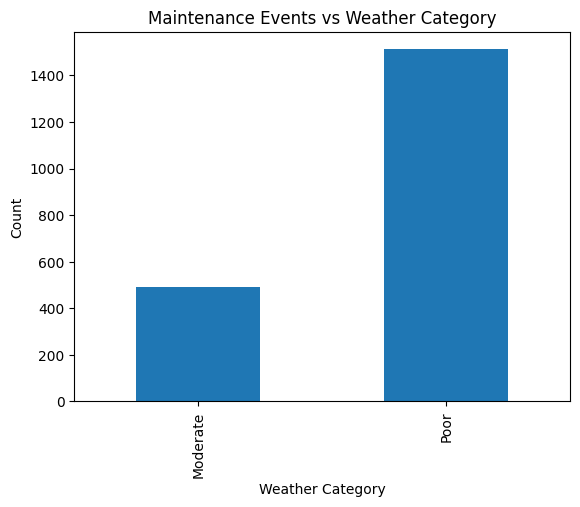

In [ ]:
weather_vs_maintenance.plot(kind='bar')
plt.title('Maintenance Events vs Weather Category')
plt.xlabel('Weather Category')
plt.ylabel('Count')
plt.show()


Plot: Anomalies vs Weather

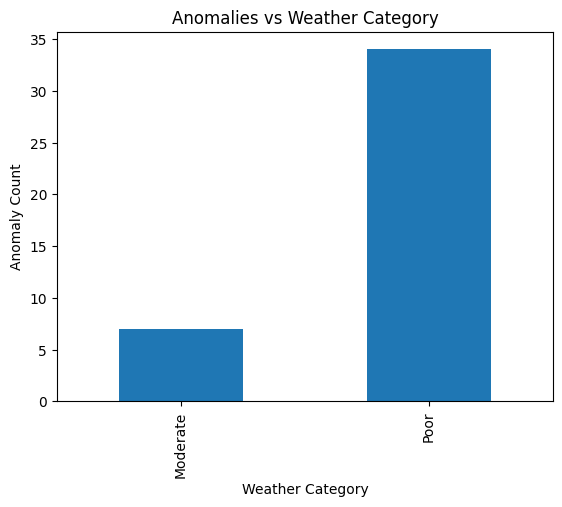

In [39]:
anomaly_vs_weather.plot(kind='bar')
plt.title('Anomalies vs Weather Category')
plt.xlabel('Weather Category')
plt.ylabel('Anomaly Count')
plt.show()


TEXT COMMENTS

### EDA Observations

- Routine A-checks dominate maintenance activities, indicating effective preventive maintenance practices.
- Unscheduled maintenance events are fewer but represent higher operational risk.
- Maintenance activity varies across aircraft and months, reflecting operational differences.
- A higher number of maintenance events and anomalies are observed under poor weather conditions.
- METAR data was synthetically generated due to the absence of real weather records; therefore, results demonstrate analytical methodology rather than real-world causality.
